# Studio di sensibilità degli iperparametri — metodi estrattivi

Questo notebook **non genera nulla**: legge i risultati scritti da `esegui_sensibilita.py` in
`risultati/` e produce le tabelle e le figure del documento `RIEPILOGO_sensibilita.md`.

Protocollo comune a tutti gli studi:

- **righe**: la split test pulita (5.610 cluster), come il benchmark;
- **lunghezza bloccata**: ogni riassunto è costruito fino alla lunghezza del riferimento e poi
  troncato al tetto di 1,25 × riferimento (stesso protocollo dell'ambito `test_budgetref`,
  issue #16), così una differenza fra due valori di un iperparametro misura la *selezione dei
  contenuti*, non la lunghezza;
- **metriche**: solo quelle lessicali di pyAutoSummarizer (ROUGE-1/2/L, BLEU, METEOR), nessuna
  metrica basata su LLM;
- **confronto**: differenza **appaiata per riga** rispetto al valore di default (quello del
  benchmark), con intervallo di confidenza al 95% bootstrap.

È un'**esplorazione qualitativa sul test**: i valori migliori trovati qui non vanno presentati
come prestazioni del metodo (sarebbero scelti guardando il test), e i numeri pubblicati del
benchmark restano quelli dei notebook originali.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CARTELLA = Path.cwd()
if not (CARTELLA / 'esegui_sensibilita.py').exists():          # avviato dalla radice del repo
    CARTELLA = CARTELLA / 'sensibilita_estrattivi'
REPO_ROOT = CARTELLA.parent
sys.path.insert(0, str(REPO_ROOT / 'notebooks'))
import summ_utils as su

SCOPE = 'test_budgetref'
METRICHE_DIR = CARTELLA / 'risultati' / 'metriche'
SELEZIONI_DIR = CARTELLA / 'risultati' / 'selezioni'
FIG_DIR = CARTELLA / 'risultati' / 'figure'
FIG_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42
N_BOOTSTRAP = 2000

# Uno studio = un iperparametro di un notebook, variato su una griglia per uno o piu' slug.
# Gli studi senza file in risultati/ vengono saltati (lo studio procede a step).
STUDI = {
    'centroid_mmr': {
        'titolo': 'Centroid+MMR (notebook 11)',
        'parametro': 'lambda', 'etichetta': 'λ', 'default': 0.7,
        'valori': [0.3, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
        'slug': ['centroid_mmr', 'centroid_mmr_bert'],
    },
    'lsa': {
        'titolo': 'LSA (notebook 15)',
        'parametro': 'k', 'etichetta': 'K_LATENTE', 'default': 11,
        'valori': [1, 2, 3, 5, 8, 11, 15, 20],
        'slug': ['lsa', 'lsa_steinberger'],
    },
    'sbert_n_cluster': {
        'titolo': 'Clustering SBERT (notebook 16)',
        'parametro': 'n_cluster', 'etichetta': 'N_CLUSTER', 'default': 11,
        'valori': [3, 5, 8, 11, 15, 20],
        'slug': ['sbert_kmeans', 'sbert_agglom'],
    },
    'sbert_linkage': {
        'titolo': 'Clustering agglomerativo SBERT (notebook 16)',
        'parametro': 'linkage', 'etichetta': 'linkage', 'default': 'average',
        'valori': ['average', 'complete', 'single'],
        'slug': ['sbert_agglom'],
        'categorico': True,      # niente curve: solo tabella
    },
    'lda_k_alfa': {
        'titolo': 'LDA (notebook 17)',
        'parametro': 'k_alfa', 'etichetta': 'N_TOPICS_alfa', 'default': '5_0.2',
        'valori': [f'{k}_{a}' for k in [2, 3, 5, 8, 11] for a in [0.05, 0.2, 0.5, 1.0]],
        'slug': ['lda'],
        'griglia': True,         # heatmap N_TOPICS x alfa invece delle curve
    },
    'lda_seme': {
        'titolo': 'LDA (notebook 17), variabilità dovuta al seme',
        'parametro': 'seme', 'etichetta': 'random_state', 'default': 42,
        'valori': [42, 0, 1, 2, 3],
        'slug': ['lda'],
        'categorico': True,
    },
}

# Metriche riportate; le tre F1 ROUGE sono quelle su cui si calcola la differenza con IC
METRICHE = ['rouge1_f1', 'rouge2_f1', 'rougeL_f1', 'bleu', 'meteor']
METRICHE_DELTA = ['rouge1_f1', 'rouge2_f1', 'rougeL_f1']
NOMI = {'rouge1_f1': 'ROUGE-1 F1', 'rouge2_f1': 'ROUGE-2 F1', 'rougeL_f1': 'ROUGE-L F1',
        'bleu': 'BLEU', 'meteor': 'METEOR'}
BANDA_INFERIORE = 0.80          # come il notebook 18: banda = [0,80 x R, tetto(R)]

COLORI = su.COLORI_METODI
INK, INK2, MUTED, GRID, SURFACE = su.INK, su.INK2, su.MUTED, su.GRID, su.SURFACE
plt.rcParams.update({'font.family': 'sans-serif', 'text.color': INK, 'axes.edgecolor': GRID,
                     'axes.labelcolor': INK2, 'xtick.color': MUTED, 'ytick.color': MUTED,
                     'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE})

# Lunghezza del riferimento per riga (serve per la banda)
P = su.percorsi_standard(REPO_ROOT)
RIF = {es['row_id']: su.budget_riferimento(es) for es in su.itera_split(P['complete_tab'], 'test')}
print(f'{len(RIF)} righe di test')

5610 righe di test


In [2]:
def slug_config(metodo, parametro, valore):
    return f'{metodo}__{parametro}-{valore}'


def carica_config(metodo, parametro, valore):
    slug = slug_config(metodo, parametro, valore)
    pe = METRICHE_DIR / f'{slug}_{SCOPE}_per_example.csv'
    sel = SELEZIONI_DIR / f'{slug}_{SCOPE}.jsonl'
    if not pe.exists() or not sel.exists():
        return None
    df = pd.read_csv(pe).set_index('row_id')
    with open(sel, encoding='utf-8') as f:
        righe = [json.loads(r) for r in f if r.strip()]
    s = pd.DataFrame(righe).drop_duplicates('row_id').set_index('row_id')
    df['scelti'] = s['scelti']
    df['ridondanza'] = s['ridondanza'].astype(float)
    return df


def jaccard(a, b):
    a, b = set(a), set(b)
    return len(a & b) / len(a | b) if a | b else 1.0


def ic_bootstrap(d, rng):
    # media e IC 95% bootstrap (percentili) di un vettore di differenze appaiate
    idx = rng.integers(0, len(d), size=(N_BOOTSTRAP, len(d)))
    medie = d[idx].mean(axis=1)
    return float(d.mean()), float(np.percentile(medie, 2.5)), float(np.percentile(medie, 97.5))


def analizza_studio(nome, studio):
    rng = np.random.default_rng(SEED)
    righe = []
    for metodo in studio['slug']:
        base = carica_config(metodo, studio['parametro'], studio['default'])
        if base is None:
            continue
        for valore in studio['valori']:
            df = carica_config(metodo, studio['parametro'], valore)
            if df is None:
                continue
            comuni = df.index.intersection(base.index)
            r = {'metodo': metodo, 'valore': valore, 'n': len(df)}
            for m in METRICHE:
                r[m] = df[m].mean()
            r['parole'] = df['parole_generate'].mean()
            R = np.array([RIF[i] for i in df.index])
            L = df['parole_generate'].to_numpy()
            tetto = np.array([su.tetto_parole(x) for x in R])
            r['in_banda'] = float(((L >= BANDA_INFERIORE * R) & (L <= tetto)).mean())
            r['meteor_negativi'] = int((df['meteor'] < 0).sum())
            for m in METRICHE_DELTA:
                d = (df.loc[comuni, m] - base.loc[comuni, m]).to_numpy()
                r[f'd_{m}'], r[f'd_{m}_lo'], r[f'd_{m}_hi'] = ic_bootstrap(d, rng)
            r['jaccard_vs_default'] = float(np.mean([jaccard(df.at[i, 'scelti'], base.at[i, 'scelti'])
                                                     for i in comuni]))
            r['quota_identiche'] = float(np.mean([set(df.at[i, 'scelti']) == set(base.at[i, 'scelti'])
                                                  for i in comuni]))
            r['ridondanza'] = float(df['ridondanza'].mean())
            r['frasi'] = float(df['scelti'].map(len).mean())
            r['parole_per_frase'] = r['parole'] / r['frasi']
            righe.append(r)
    return pd.DataFrame(righe)


RISULTATI = {}
for nome, studio in STUDI.items():
    tab = analizza_studio(nome, studio)
    if tab.empty:
        print(f'{nome}: nessun risultato, saltato')
        continue
    RISULTATI[nome] = tab
    print(f'{nome}: {len(tab)} configurazioni')

centroid_mmr: 14 configurazioni


lsa: 16 configurazioni


sbert_n_cluster: 12 configurazioni


sbert_linkage: 3 configurazioni


lda_k_alfa: 20 configurazioni


lda_seme: 5 configurazioni


## Tabelle

Per ogni configurazione: medie delle metriche sul testo post-tetto, lunghezza media, quota di
righe nella banda [0,80 × R, tetto], differenza appaiata rispetto al default con IC 95%,
similarità di Jaccard fra le frasi scelte e quelle del default, quota di righe con selezione
identica al default, ridondanza interna media (coseno medio fra le frasi scelte, nello spazio
di rappresentazione del metodo) e lunghezza media delle frasi scelte.

In [3]:
def formatta(tab, studio):
    t = tab.copy()
    out = pd.DataFrame({'metodo': t['metodo'], studio['etichetta']: t['valore']})
    for m in METRICHE:
        out[NOMI[m]] = t[m].map('{:.4f}'.format)
    for m in METRICHE_DELTA:
        out['Δ ' + NOMI[m]] = [f'{v:+.4f} [{lo:+.4f}, {hi:+.4f}]'
                               for v, lo, hi in zip(t[f'd_{m}'], t[f'd_{m}_lo'], t[f'd_{m}_hi'])]
    out['parole'] = t['parole'].map('{:.1f}'.format)
    out['parole/frase'] = t['parole_per_frase'].map('{:.1f}'.format)
    out['in banda'] = t['in_banda'].map('{:.1%}'.format)
    out['Jaccard vs default'] = t['jaccard_vs_default'].map('{:.3f}'.format)
    out['identiche al default'] = t['quota_identiche'].map('{:.1%}'.format)
    out['ridondanza'] = t['ridondanza'].map('{:.3f}'.format)
    return out


pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 30)
for nome, tab in RISULTATI.items():
    print(f'=== {STUDI[nome]["titolo"]} ===')
    display(formatta(tab, STUDI[nome]).set_index(['metodo', STUDI[nome]['etichetta']]))

=== Centroid+MMR (notebook 11) ===


ROUGE-1 F1 ROUGE-2 F1 ROUGE-L F1    BLEU  METEOR                Δ ROUGE-1 F1                Δ ROUGE-2 F1                Δ ROUGE-L F1 parole parole/frase in banda Jaccard vs default identiche al default ridondanza
metodo            λ                                                                                                                                                                                                                       
centroid_mmr      0.3     0.3651     0.1228     0.1853  0.1088  0.4048  -0.0129 [-0.0145, -0.0112]  -0.0140 [-0.0157, -0.0124]  -0.0121 [-0.0134, -0.0106]  214.9         22.0    98.7%              0.205                 2.6%      0.011
                  0.5     0.3782     0.1345     0.1945  0.1152  0.4168  +0.0003 [-0.0011, +0.0016]  -0.0022 [-0.0034, -0.0010]  -0.0029 [-0.0040, -0.0019]  215.0         29.8    97.9%              0.475                 7.1%      0.047
                  0.6     0.3788     0.1364     0.1965  0.1159  0.4162  +0.0009 [-0.0000, +0.0018]  -0.0004 [-0.0013, +0.0005]  -0.0009 [-0.0016, -0.0001]  215.0         31.9    97.8%              0.698                22.8%      0.072
                  0.7     0.3779     0.1368     0.1974  0.1154  0.4126  +0.0000 [+0.0000, +0.0000]  +0.0000 [+0.0000, +0.0000]  +0.0000 [+0.0000, +0.0000]  215.2         32.4    97.8%              1.000               100.0%      0.095
                  0.8     0.3751     0.1355     0.1966  0.1138  0.4078  -0.0028 [-0.0037, -0.0020]  -0.0013 [-0.0021, -0.0005]  -0.0007 [-0.0015, -0.0001]  214.9         32.2    97.8%              0.756                29.1%      0.118
                  0.9     0.3708     0.1331     0.1958  0.1108  0.4007  -0.0071 [-0.0081, -0.0060]  -0.0037 [-0.0048, -0.0026]  -0.0015 [-0.0024, -0.0006]  215.1         31.5    97.9%              0.629                13.4%      0.144
                  1.0     0.3655     0.1306     0.1943  0.1079  0.3924  -0.0124 [-0.0138, -0.0111]  -0.0062 [-0.0074, -0.0050]  -0.0030 [-0.0041, -0.0020]  215.2         30.7    97.9%              0.539                 7.1%      0.171
centroid_mmr_bert 0.3     0.3361     0.1065     0.1744  0.1001  0.3832  -0.0282 [-0.0299, -0.0263]  -0.0203 [-0.0221, -0.0186]  -0.0174 [-0.0187, -0.0159]  214.9         19.2    98.7%              0.120                 1.8%      0.149
                  0.5     0.3575     0.1208     0.1862  0.1090  0.4074  -0.0067 [-0.0082, -0.0052]  -0.0061 [-0.0075, -0.0047]  -0.0056 [-0.0068, -0.0044]  215.3         27.5    98.6%              0.303                 2.5%      0.332
                  0.6     0.3635     0.1259     0.1903  0.1109  0.4125  -0.0007 [-0.0018, +0.0003]  -0.0010 [-0.0020, -0.0000]  -0.0015 [-0.0024, -0.0007]  215.1         31.5    98.1%              0.609                12.8%      0.446
                  0.7     0.3643     0.1269     0.1918  0.1105  0.4132  +0.0000 [+0.0000, +0.0000]  +0.0000 [+0.0000, +0.0000]  +0.0000 [+0.0000, +0.0000]  215.0         33.0    97.9%              1.000               100.0%      0.503
                  0.8     0.3628     0.1264     0.1917  0.1097  0.4104  -0.0014 [-0.0023, -0.0005]  -0.0005 [-0.0013, +0.0004]  -0.0001 [-0.0008, +0.0007]  214.7         33.4    97.7%              0.731                25.5%      0.537
                  0.9     0.3617     0.1261     0.1920  0.1087  0.4081  -0.0025 [-0.0036, -0.0014]  -0.0008 [-0.0019, +0.0002]  +0.0002 [-0.0007, +0.0010]  215.0         33.4    97.8%              0.626                13.3%      0.559
                  1.0     0.3594     0.1247     0.1912  0.1072  0.4045  -0.0048 [-0.0060, -0.0036]  -0.0021 [-0.0033, -0.0010]  -0.0006 [-0.0015, +0.0003]  214.9         33.2    97.8%              0.561                 8.1%      0.575

=== LSA (notebook 15) ===


ROUGE-1 F1 ROUGE-2 F1 ROUGE-L F1    BLEU  METEOR                Δ ROUGE-1 F1                Δ ROUGE-2 F1                Δ ROUGE-L F1 parole parole/frase in banda Jaccard vs default identiche al default ridondanza
metodo          K_LATENTE                                                                                                                                                                                                                     
lsa             1             0.3563     0.1266     0.1916  0.1052  0.3786  +0.0059 [+0.0040, +0.0081]  +0.0020 [+0.0000, +0.0039]  +0.0034 [+0.0018, +0.0049]  214.9         28.2    97.7%              0.240                 1.7%      0.194
                2             0.3546     0.1263     0.1906  0.1054  0.3760  +0.0043 [+0.0023, +0.0062]  +0.0017 [-0.0000, +0.0035]  +0.0024 [+0.0009, +0.0038]  215.0         25.6    97.9%              0.318                 2.1%      0.172
                3             0.3549     0.1270     0.1908  0.1069  0.3753  +0.0046 [+0.0029, +0.0064]  +0.0024 [+0.0008, +0.0041]  +0.0026 [+0.0012, +0.0040]  214.8         24.1    97.8%              0.386                 2.8%      0.153
                5             0.3549     0.1274     0.1902  0.1079  0.3746  +0.0045 [+0.0030, +0.0061]  +0.0028 [+0.0014, +0.0043]  +0.0020 [+0.0009, +0.0032]  214.7         22.6    98.0%              0.507                 5.4%      0.131
                8             0.3534     0.1265     0.1893  0.1084  0.3736  +0.0030 [+0.0018, +0.0042]  +0.0019 [+0.0009, +0.0031]  +0.0011 [+0.0002, +0.0020]  214.7         21.6    98.2%              0.671                12.6%      0.113
                11            0.3503     0.1246     0.1882  0.1082  0.3712  +0.0000 [+0.0000, +0.0000]  +0.0000 [+0.0000, +0.0000]  +0.0000 [+0.0000, +0.0000]  214.8         20.9    98.4%              1.000               100.0%      0.100
                15            0.3442     0.1206     0.1848  0.1066  0.3678  -0.0062 [-0.0074, -0.0049]  -0.0040 [-0.0051, -0.0028]  -0.0034 [-0.0043, -0.0025]  215.0         20.3    98.5%              0.651                13.0%      0.089
                20            0.3351     0.1144     0.1809  0.1033  0.3623  -0.0152 [-0.0168, -0.0136]  -0.0102 [-0.0117, -0.0087]  -0.0073 [-0.0086, -0.0061]  214.7         19.7    98.4%              0.506                 8.1%      0.076
lsa_steinberger 1             0.3563     0.1266     0.1916  0.1052  0.3786  -0.0131 [-0.0152, -0.0110]  -0.0058 [-0.0077, -0.0038]  +0.0005 [-0.0011, +0.0021]  214.9         28.2    97.7%              0.162                 1.1%      0.194
                2             0.3572     0.1273     0.1913  0.1058  0.3792  -0.0122 [-0.0141, -0.0103]  -0.0050 [-0.0069, -0.0032]  +0.0001 [-0.0014, +0.0016]  215.1         25.6    98.0%              0.200                 1.1%      0.159
                3             0.3602     0.1292     0.1920  0.1079  0.3814  -0.0092 [-0.0111, -0.0073]  -0.0031 [-0.0049, -0.0014]  +0.0009 [-0.0006, +0.0024]  214.7         24.2    98.0%              0.243                 1.4%      0.130
                5             0.3651     0.1311     0.1924  0.1105  0.3890  -0.0043 [-0.0060, -0.0026]  -0.0012 [-0.0028, +0.0004]  +0.0013 [-0.0001, +0.0026]  214.7         22.8    98.4%              0.334                 1.9%      0.088
                8             0.3712     0.1342     0.1933  0.1159  0.4007  +0.0018 [+0.0006, +0.0031]  +0.0018 [+0.0006, +0.0031]  +0.0022 [+0.0011, +0.0033]  214.7         21.9    98.4%              0.505                 4.6%      0.051
                11            0.3694     0.1323     0.1911  0.1169  0.4039  +0.0000 [+0.0000, +0.0000]  +0.0000 [+0.0000, +0.0000]  +0.0000 [+0.0000, +0.0000]  215.1         21.6    98.8%              1.000               100.0%      0.032
                15            0.3635     0.1280     0.1878  0.1152  0.4010  -0.0059 [-0.0071, -0.0046]  -0.0044 [-0.0056, -0.0032]  -0.0033 [-0.0043, -0.0024]  214.6         21.1    98.6%              0

=== Clustering SBERT (notebook 16) ===


...

ROUGE-1 F1 ROUGE-2 F1 ROUGE-L F1    BLEU  METEOR                Δ ROUGE-1 F1                Δ ROUGE-2 F1                Δ ROUGE-L F1 parole parole/frase in banda Jaccard vs default identiche al default ridondanza
metodo       linkage                                                                                                                                                                                                                      
sbert_agglom average      0.3397     0.1109     0.1788  0.1026  0.3872  +0.0000 [+0.0000, +0.0000]  +0.0000 [+0.0000, +0.0000]  +0.0000 [+0.0000, +0.0000]  214.8         19.9    98.6%              1.000               100.0%      0.187
             complete     0.3527     0.1184     0.1846  0.1062  0.4015  +0.0130 [+0.0115, +0.0144]  +0.0075 [+0.0062, +0.0088]  +0.0059 [+0.0048, +0.0070]  215.0         23.2    98.5%              0.368                 5.2%      0.247
             single       0.3272     0.1030     0.1732  0.0973  0.3757  -0.0125 [-0.0140, -0.0110]  -0.0079 [-0.0093, -0.0065]  -0.0055 [-0.0067, -0.0043]  214.8         19.1    98.6%              0.391                 3.5%      0.172

=== LDA (notebook 17) ===


ROUGE-1 F1 ROUGE-2 F1 ROUGE-L F1    BLEU    METEOR                Δ ROUGE-1 F1                Δ ROUGE-2 F1                Δ ROUGE-L F1 parole parole/frase in banda Jaccard vs default identiche al default ridondanza
metodo N_TOPICS_alfa                                                                                                                                                                                                                       
lda    2_0.05            0.3330     0.1105     0.1784  0.0989  -13.4940  -0.0052 [-0.0067, -0.0036]  -0.0022 [-0.0035, -0.0008]  -0.0012 [-0.0023, -0.0000]  220.7         50.2    99.4%              0.383                 1.9%      0.123
       2_0.2             0.3332     0.1105     0.1784  0.0990  -13.4938  -0.0050 [-0.0065, -0.0036]  -0.0022 [-0.0036, -0.0007]  -0.0011 [-0.0023, +0.0001]  220.7         50.0    99.4%              0.384                 2.0%      0.121
       2_0.5             0.3284     0.1075     0.1760  0.0974    0.3748  -0.0098 [-0.0115, -0.0083]  -0.0052 [-0.0066, -0.0038]  -0.0035 [-0.0046, -0.0023]  220.5         48.5    99.4%              0.353                 1.7%      0.105
       2_1.0             0.3255     0.1055     0.1746  0.0969    0.3719  -0.0127 [-0.0143, -0.0110]  -0.0071 [-0.0086, -0.0056]  -0.0050 [-0.0063, -0.0038]  220.3         46.5    99.4%              0.322                 1.5%      0.093
       3_0.05            0.3356     0.1118     0.1793  0.0988  -13.4882  -0.0026 [-0.0041, -0.0011]  -0.0009 [-0.0022, +0.0005]  -0.0002 [-0.0013, +0.0009]  224.2         47.5    99.3%              0.420                 2.3%      0.111
       3_0.2             0.3346     0.1110     0.1789  0.0984  -13.4889  -0.0035 [-0.0049, -0.0021]  -0.0016 [-0.0030, -0.0002]  -0.0007 [-0.0018, +0.0004]  224.1         47.2    99.3%              0.422                 2.5%      0.109
       3_0.5             0.3297     0.1080     0.1765  0.0972  -13.4927  -0.0085 [-0.0100, -0.0069]  -0.0046 [-0.0060, -0.0032]  -0.0031 [-0.0042, -0.0020]  224.1         45.9    99.3%              0.387                 1.9%      0.092
       3_1.0             0.3271     0.1065     0.1753  0.0965  -13.4951  -0.0111 [-0.0126, -0.0095]  -0.0062 [-0.0076, -0.0046]  -0.0043 [-0.0055, -0.0030]  224.2         44.2    99.3%              0.342                 1.5%      0.080
       5_0.05            0.3389     0.1135     0.1797  0.0986  -13.4801  +0.0007 [-0.0002, +0.0016]  +0.0008 [-0.0000, +0.0017]  +0.0001 [-0.0006, +0.0008]  229.2         42.7    99.2%              0.741                31.6%      0.098
       5_0.2             0.3382     0.1127     0.1795  0.0983  -13.4805  +0.0000 [+0.0000, +0.0000]  +0.0000 [+0.0000, +0.0000]  +0.0000 [+0.0000, +0.0000]  229.6         42.5    99.2%              1.000               100.0%      0.095
       5_0.5             0.3338     0.1104     0.1775  0.0971    0.3955  -0.0043 [-0.0056, -0.0031]  -0.0023 [-0.0034, -0.0012]  -0.0021 [-0.0030, -0.0011]  229.8         41.4    99.1%              0.580                13.9%      0.079
       5_1.0             0.3312     0.1091     0.1770  0.0974    0.3932  -0.0070 [-0.0084, -0.0056]  -0.0036 [-0.0048, -0.0022]  -0.0026 [-0.0037, -0.0015]  229.7         40.3    99.2%              0.459                 6.4%      0.067
       8_0.05            0.3390     0.1134     0.1797  0.0984    0.3334  +0.0008 [-0.0007, +0.0024]  +0.0007 [-0.0007, +0.0022]  +0.0002 [-0.0011, +0.0014]  227.7         37.7    98.7%              0.329                 2.0%      0.088
       8_0.2             0.3379     0.1128     0.1794  0.0978    0.3959  -0.0003 [-0.0018, +0.0012]  +0.0002 [-0.0013, +0.0017]  -0.0001 [-0.0013, +0.0011]  228.1         37.2    98.6%              0.345                 2.0%      0.084
       8_0.5             0.3344     0.1100     0.1776  0.0964    0.3953  -0.0037 [-0.0053, -0.0021]  -0.0027 [-0.0041, -0.0012]  -0.0020 [-0.0032, -0.0008]  229.7         35.7    98.8%              0.329                 2.0%      0.068
       8_

=== LDA (notebook 17), variabilità dovuta al seme ===


ROUGE-1 F1 ROUGE-2 F1 ROUGE-L F1    BLEU    METEOR                Δ ROUGE-1 F1                Δ ROUGE-2 F1                Δ ROUGE-L F1 parole parole/frase in banda Jaccard vs default identiche al default ridondanza
metodo random_state                                                                                                                                                                                                                       
lda    42               0.3382     0.1127     0.1795  0.0983  -13.4805  +0.0000 [+0.0000, +0.0000]  +0.0000 [+0.0000, +0.0000]  +0.0000 [+0.0000, +0.0000]  229.6         42.5    99.2%              1.000               100.0%      0.095
       0                0.3384     0.1126     0.1795  0.0978  -13.4802  +0.0002 [-0.0014, +0.0018]  -0.0000 [-0.0016, +0.0015]  -0.0001 [-0.0013, +0.0012]  229.6         42.4    99.1%              0.317                 1.6%      0.095
       1                0.3385     0.1130     0.1792  0.0986  -13.4799  +0.0003 [-0.0013, +0.0020]  +0.0003 [-0.0012, +0.0018]  -0.0003 [-0.0015, +0.0009]  230.0         42.5    99.2%              0.320                 1.6%      0.096
       2                0.3377     0.1126     0.1790  0.0984  -13.4819  -0.0004 [-0.0022, +0.0012]  -0.0000 [-0.0015, +0.0015]  -0.0005 [-0.0017, +0.0008]  229.6         42.6    99.2%              0.318                 1.8%      0.095
       3                0.3379     0.1125     0.1789  0.0982  -13.4824  -0.0003 [-0.0019, +0.0014]  -0.0001 [-0.0017, +0.0015]  -0.0006 [-0.0019, +0.0007]  229.4         42.5    99.2%              0.315                 1.8%      0.095

## Figure

Per ogni studio due figure: (1) la differenza appaiata rispetto al default per le tre F1 ROUGE,
con l'intervallo di confidenza come banda; (2) quanto cambia la selezione (Jaccard con il
default) e le sue proprietà (ridondanza interna, lunghezza media delle frasi). Una serie per
slug, con il colore del metodo usato in tutto il benchmark.

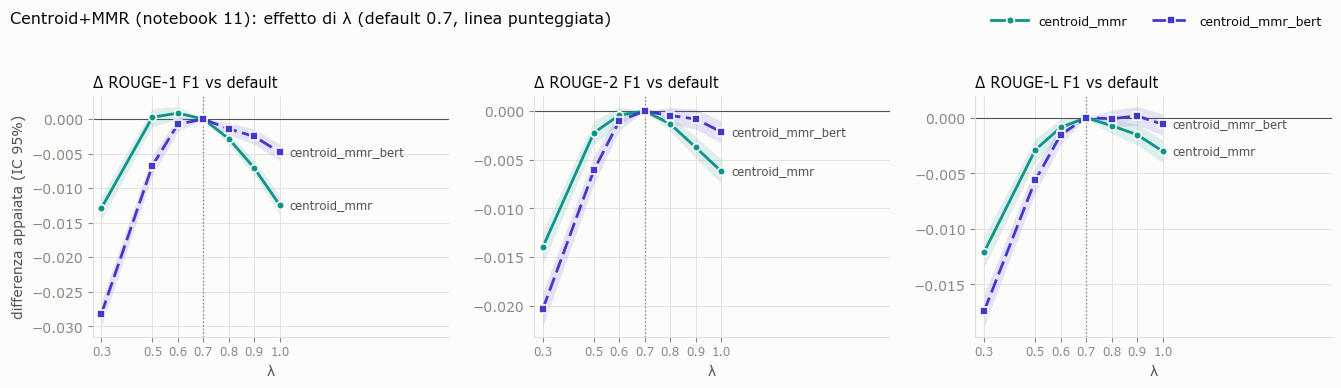

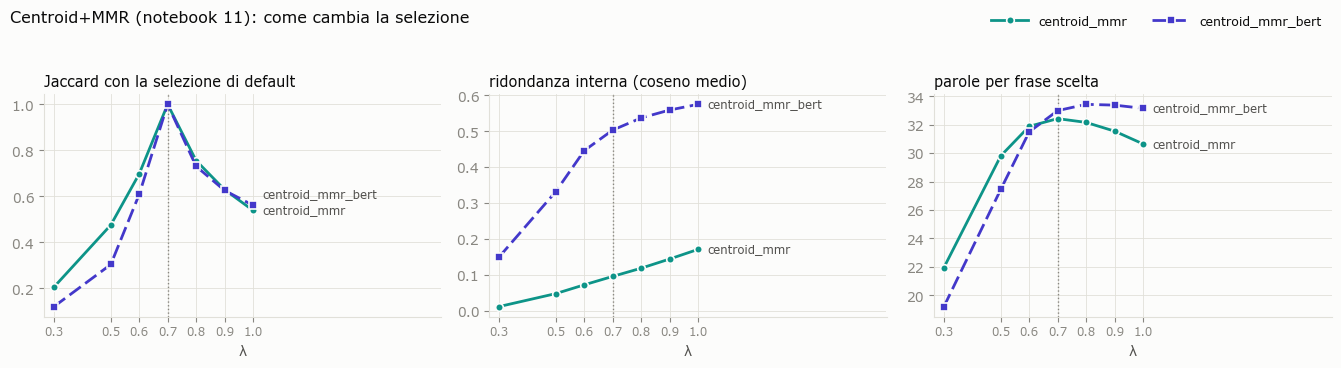

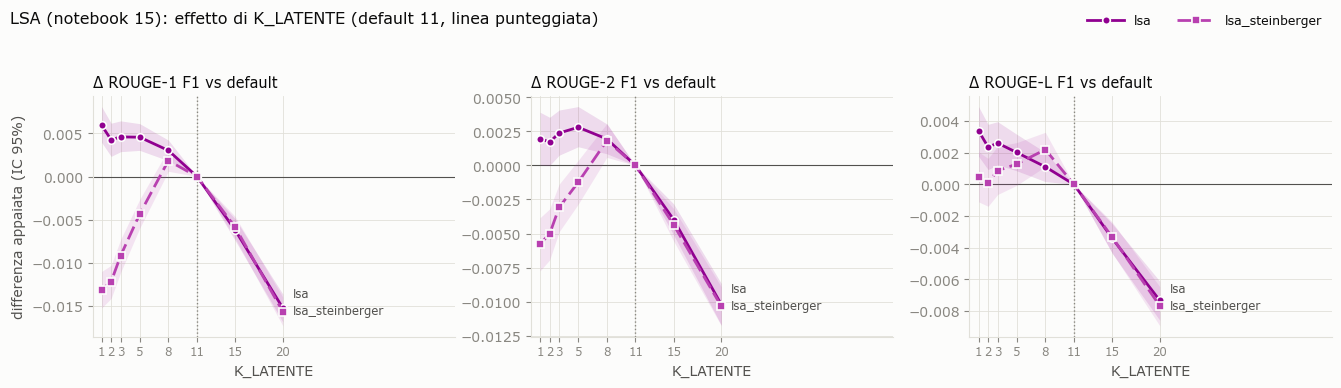

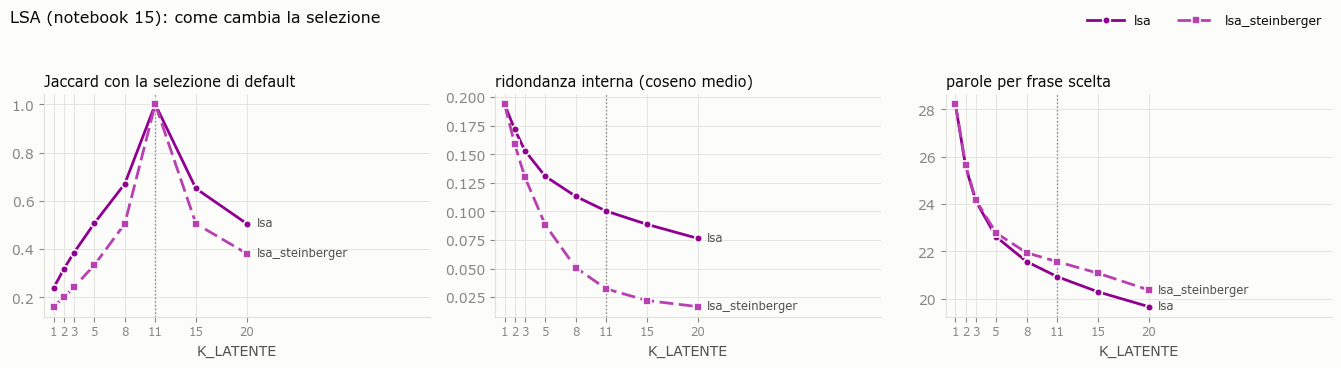

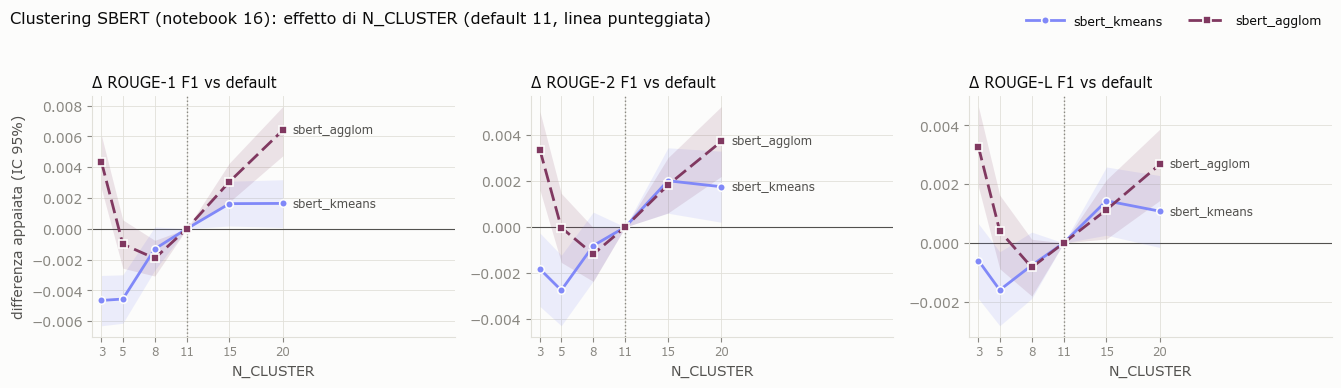

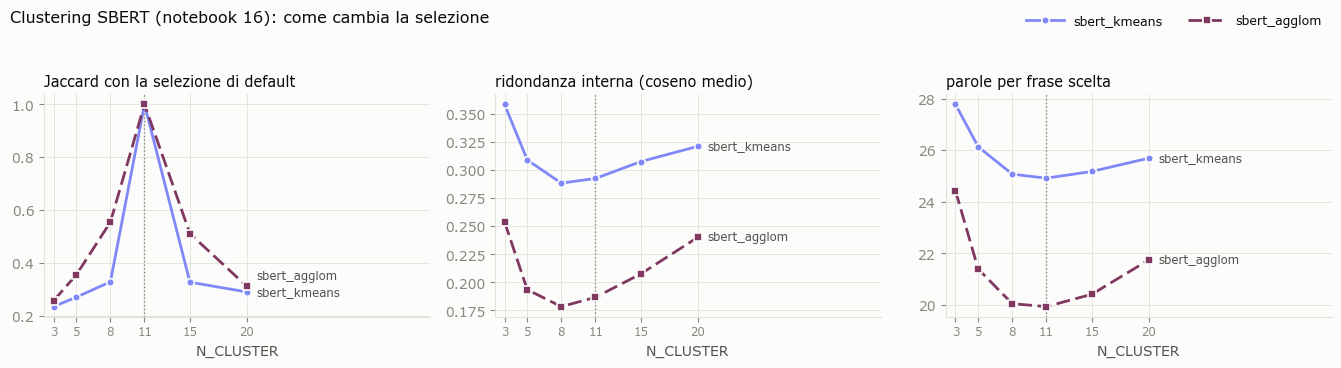

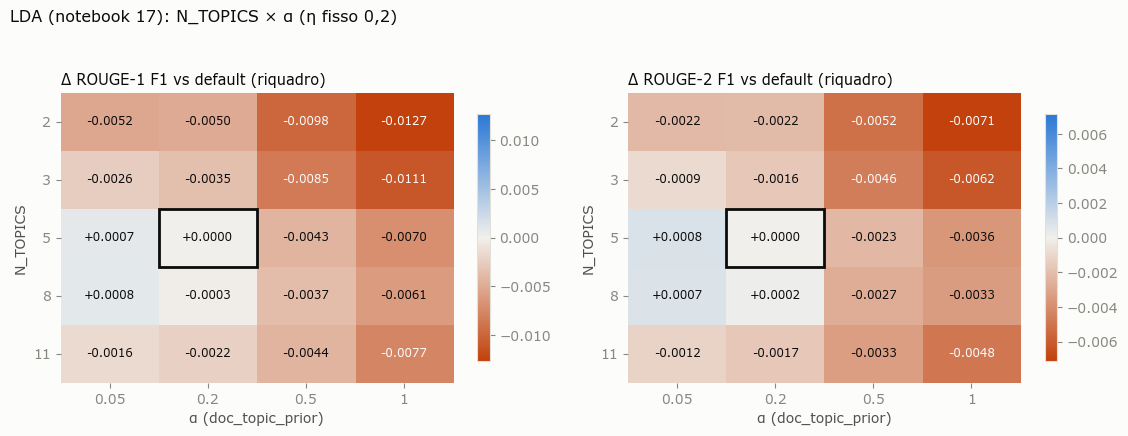

In [4]:
def _assi(ax, titolo, studio):
    ax.set_title(titolo, loc='left', fontsize=10.5, color=INK)
    ax.set_xlabel(studio['etichetta'])
    ax.grid(True, color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
    ax.axvline(studio['default'], color=MUTED, linewidth=1, linestyle=':', zorder=1)
    ax.set_xticks(studio['valori'])
    ax.tick_params(axis='x', labelsize=8.5)


# Codifica secondaria per slug dello stesso studio (i colori di due varianti possono essere
# vicini): il primo slug linea piena e cerchi, il secondo tratteggio e quadrati
STILI = [{'linestyle': '-', 'marker': 'o'}, {'linestyle': (0, (5, 2)), 'marker': 's'}]


def _etichette_finali(ax, punti):
    # Etichette dirette all'estremo destro delle serie, distanziate se si sovrappongono:
    # `punti` = [(x, y, testo)], distanza minima 7% dell'escursione verticale
    if not punti:
        return
    y0, y1 = ax.get_ylim()
    gap = 0.07 * (y1 - y0)
    ordinati = sorted(punti, key=lambda p: p[1])
    pos = [p[1] for p in ordinati]
    for i in range(1, len(pos)):
        if pos[i] - pos[i - 1] < gap:
            pos[i] = pos[i - 1] + gap
    for (x, y, testo), yy in zip(ordinati, pos):
        ax.annotate(testo, (x, yy), xytext=(7, 0), textcoords='offset points', va='center',
                    fontsize=8.5, color=INK2)
    x0, x1 = ax.get_xlim()
    ax.set_xlim(x0, x1 + 0.22 * (x1 - x0))


def _linea(ax, g, col, metodo, k):
    ax.plot(g['valore'], g[col], color=COLORI.get(metodo, INK), linewidth=2, markersize=5.5,
            markeredgecolor=SURFACE, markeredgewidth=1.2, label=metodo, zorder=3,
            **STILI[k % len(STILI)])


def _legenda(fig, ax):
    maniglie, etichette = ax.get_legend_handles_labels()
    fig.legend(maniglie, etichette, frameon=False, fontsize=9, ncol=len(etichette),
               loc='upper right', bbox_to_anchor=(0.99, 1.0), handlelength=3)


def figura_delta(nome, tab, studio):
    fig, assi = plt.subplots(1, 3, figsize=(13.5, 3.9), sharex=True)
    for ax, m in zip(assi, METRICHE_DELTA):
        ax.axhline(0, color=INK2, linewidth=0.8, zorder=1)
        punti = []
        for k, (metodo, g) in enumerate(tab.groupby('metodo', sort=False)):
            g = g.sort_values('valore')
            ax.fill_between(g['valore'], g[f'd_{m}_lo'], g[f'd_{m}_hi'],
                            color=COLORI.get(metodo, INK), alpha=0.13, linewidth=0, zorder=2)
            _linea(ax, g, f'd_{m}', metodo, k)
            punti.append((g['valore'].iloc[-1], g[f'd_{m}'].iloc[-1], metodo))
        _assi(ax, f'Δ {NOMI[m]} vs default', studio)
        _etichette_finali(ax, punti)
    assi[0].set_ylabel('differenza appaiata (IC 95%)')
    _legenda(fig, assi[0])
    fig.suptitle(f'{studio["titolo"]}: effetto di {studio["etichetta"]} '
                 f'(default {studio["default"]}, linea punteggiata)', x=0.01, ha='left',
                 fontsize=11.5, color=INK)
    fig.tight_layout(rect=(0, 0, 1, 0.93))
    fig.savefig(FIG_DIR / f'{nome}_delta.png', dpi=150, bbox_inches='tight', facecolor=SURFACE)
    plt.show()


def figura_selezione(nome, tab, studio):
    pannelli = [('jaccard_vs_default', 'Jaccard con la selezione di default'),
                ('ridondanza', 'ridondanza interna (coseno medio)'),
                ('parole_per_frase', 'parole per frase scelta')]
    fig, assi = plt.subplots(1, 3, figsize=(13.5, 3.7), sharex=True)
    for ax, (col, titolo) in zip(assi, pannelli):
        punti = []
        for k, (metodo, g) in enumerate(tab.groupby('metodo', sort=False)):
            g = g.sort_values('valore')
            _linea(ax, g, col, metodo, k)
            punti.append((g['valore'].iloc[-1], g[col].iloc[-1], metodo))
        _assi(ax, titolo, studio)
        _etichette_finali(ax, punti)
    _legenda(fig, assi[0])
    fig.suptitle(f'{studio["titolo"]}: come cambia la selezione', x=0.01, ha='left',
                 fontsize=11.5, color=INK)
    fig.tight_layout(rect=(0, 0, 1, 0.93))
    fig.savefig(FIG_DIR / f'{nome}_selezione.png', dpi=150, bbox_inches='tight', facecolor=SURFACE)
    plt.show()


from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

# Divergente: due poli + un neutro chiaro al centro (lo zero = nessuna differenza dal default)
DIVERGENTE = LinearSegmentedColormap.from_list('div', ['#c2410c', '#f1f0ec', '#2a78d6'])


def figura_griglia(nome, tab, studio):
    t = tab.copy()
    t['k'] = t['valore'].map(lambda v: int(v.split('_')[0]))
    t['alfa'] = t['valore'].map(lambda v: float(v.split('_')[1]))
    k_def, a_def = studio['default'].split('_')
    fig, assi = plt.subplots(1, 2, figsize=(11.5, 4.4))
    for ax, m in zip(assi, ['rouge1_f1', 'rouge2_f1']):
        M = t.pivot(index='k', columns='alfa', values=f'd_{m}').sort_index()
        lim = float(np.nanmax(np.abs(M.values))) or 1e-3
        im = ax.imshow(M.values, cmap=DIVERGENTE, norm=TwoSlopeNorm(0, -lim, lim), aspect='auto')
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                v = M.values[i, j]
                ax.text(j, i, f'{v:+.4f}', ha='center', va='center', fontsize=8.5,
                        color=INK if abs(v) < 0.6 * lim else SURFACE)
        i0, j0 = list(M.index).index(int(k_def)), list(M.columns).index(float(a_def))
        ax.add_patch(plt.Rectangle((j0 - 0.5, i0 - 0.5), 1, 1, fill=False, edgecolor=INK, linewidth=2))
        ax.set_xticks(range(M.shape[1]), [f'{a:g}' for a in M.columns])
        ax.set_yticks(range(M.shape[0]), M.index)
        ax.set_xlabel('α (doc_topic_prior)')
        ax.set_ylabel('N_TOPICS')
        ax.set_title(f'Δ {NOMI[m]} vs default (riquadro)', loc='left', fontsize=10.5, color=INK)
        for sp in ax.spines.values():
            sp.set_visible(False)
        fig.colorbar(im, ax=ax, shrink=0.85)
    fig.suptitle(f'{studio["titolo"]}: N_TOPICS × α (η fisso 0,2)', x=0.01, ha='left',
                 fontsize=11.5, color=INK)
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    fig.savefig(FIG_DIR / f'{nome}_griglia.png', dpi=150, bbox_inches='tight', facecolor=SURFACE)
    plt.show()


for nome, tab in RISULTATI.items():
    if STUDI[nome].get('categorico'):
        continue
    if STUDI[nome].get('griglia'):
        figura_griglia(nome, tab, STUDI[nome])
        continue
    figura_delta(nome, tab, STUDI[nome])
    figura_selezione(nome, tab, STUDI[nome])

In [5]:
# Riepilogo macchina-leggibile, letto dal documento RIEPILOGO_sensibilita.md
riepilogo = {nome: {'studio': STUDI[nome], 'configurazioni': tab.to_dict(orient='records')}
             for nome, tab in RISULTATI.items()}
(CARTELLA / 'risultati' / 'riepilogo.json').write_text(
    json.dumps(riepilogo, indent=2, ensure_ascii=False), encoding='utf-8')
print('Scritto risultati/riepilogo.json')

Scritto risultati/riepilogo.json
